# Práctica 4 - Anatomía de un dataset de Machine Learning
**Sesión 4 - El dataset**

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino **interpretar correctamente los datos**.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [1]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# TODO: carga clientes_ecommerce.csv en df
df = pd.read_csv("clientes_ecommerce.csv")

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [2]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


### Respuesta
1. ¿Qué representa una fila?
Cada fila representa a un cliente
2. ¿Qué representa una columna?
Una columna representa un atributo de cada cliente
3. ¿Cuál es la unidad de observación?
La unidad de observación es el propio cliente
4. ¿Todas las columnas son características? Justifica.
No, de las 12 columnas, 2 de ellas no son características: `cliente_id` es un identificador que solo sirve para distinguir a cada cliente, y `compra_proximo_mes` es el target, la variable que queremos predecir. Las 10 restantes sí son características.

**Respuesta:** En el dataset cada fila representa a un cliente diferente, y cada de las columnas de este dataset representa un atributo o característica de los clientes. Por tanto, la unidad de observación es el propio cliente, lo que significa que cada fila recoge información propia del cliente como qué edad tiene, sus ingresos anuales, la zona donde vive, etc. Pese a ello, todos los atributos no son características, la columna `cliente_id` es un identificador del cliente

### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

### Respuesta
- Número de muestras: 400
- Número de columnas: 12
- ¿Tenemos el mismo número de características? ¿Por qué?

No, `df.shape` nos devuelve 400 muestras o filas y 12 columnas en una tupla de esta forma: `(400, 12)`, pero no todas las columnas son características. Por un lado, `cliente_id` solo da información para identificar a clientes distintos, por tanto, no aporta ninguna información extra sobre su comportamiento. Por otro lado, tenemos la columna `compra_proximo_mes` que es el target, la variable objetivo que queremos predecir, por lo que tampoco puede usarse como dato de entrada (X). Por tanto, de las 12 columnas solo se queda en 10 características.

## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [4]:
# TODO: consulta df.dtypes
for columna, tipo in df.dtypes.items():
    print(f"{columna}: {tipo}")

cliente_id: int64
edad: int64
antiguedad_meses: float64
ingresos_anuales: float64
gasto_mensual: float64
num_compras: int64
devoluciones: int64
dispositivo: str
zona: str
nivel_fidelidad: str
satisfaccion: int64
compra_proximo_mes: str


### Ficha de variables
Clasifica cada variable como: **Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target**.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | int64 | Identificador | No |
| edad | int64 | Numérica discreta | Sí |
| antiguedad_meses | float64 | Numérica discreta | Sí |
| ingresos_anuales | float64 | Numérica continua | Sí |
| gasto_mensual | float64 | Numérica continua | Sí |
| num_compras | int64 | Numérica discreta | Sí |
| devoluciones | int64 | Numérica discreta | Sí |
| dispositivo | str | Categórica nominal| Sí |
| zona | str | Categórica nominal | Sí |
| nivel_fidelidad | str | Categórica ordinal | Sí |
| satisfaccion | int64 | Categórica ordinal | Sí |
| compra_proximo_mes | str | Target | No |

No clasifiques únicamente por `dtype`.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [5]:
# TODO: analiza cliente_id
print(f"Primeros 10 valores: {df["cliente_id"].head(10)}")
print(f"Tipo de dato: {df["cliente_id"].dtype}")
print(f"¿Tiene valores únicos?: {df["cliente_id"].is_unique}")
print(f"Media: {df["cliente_id"].mean()}")

Primeros 10 valores: 0    20001
1    20002
2    20003
3    20004
4    20005
5    20006
6    20007
7    20008
8    20009
9    20010
Name: cliente_id, dtype: int64
Tipo de dato: int64
¿Tiene valores únicos?: True
Media: 20200.5


### Respuesta
1. ¿Qué dtype tiene?
int64
2. ¿Es por ello cuantitativa?
El ID del cliente es una etiqueta identificadora, por tanto no es cuantitativa
3. ¿Tiene sentido calcular su media?
No tiene sentido ya que es una etiqueta de identificación de un cliente
4. ¿La incluirías inicialmente en \(X\)?
No porque no es una variable medible para el modelo
5. Justifica.

La columna `cliente_id` aunque su tipo de dato es `int64`, se considera un identificador, una etiqueta propia del cliente, por tanto no sería una variable medible para la predicción del modelo

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [6]:
# TODO: value_counts() + sort_index()
print(f"Frecuencia del nivel de satisfacción: {df["satisfaccion"].value_counts().sort_index()}")

Frecuencia del nivel de satisfacción: satisfaccion
1     33
2     58
3    123
4    116
5     70
Name: count, dtype: int64


Sabemos que 1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho.

### Respuesta
1. ¿Cómo la almacena pandas?
La satisfacción la almacena pandas como `int64`
2. ¿Es simplemente numérica?
No, es una variable categórica ordinal
3. ¿Existe un orden?
Sí, los valores de la columna `satisfacción` siguen el siguiente orden de menor a mayor: 1 (Muy insatisfecho), 2 (Insatisfecho), 3 (Neutral), 4 (Satisfecho) y 5 (Muy satisfecho).
4. ¿Nominal u ordinal?
Es una variable de tipo categórica ordinal
5. Explica `dtype` frente a significado conceptual.

Pandas la guarda como `int64`, pero no es una variable numérica, es decir cada número es una etiqueta que representa un nivel de satisfacción (1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho), no es una cantidad para que sea numérica. Esta variable tiene orden en cuanto a la calificación que le dan los clientes por eso es una variable categórica ordinal.
La diferencia es que el `dtype` indica cómo almacena pandas el dato técnicamente, que en este caso es un entero, mientras que el significado conceptual indica qué representa realmente y cómo debe tratarse el dato, lo que se le llama `calidad del dato`. Aunque `satisfaccion` se guarde como número, es una escala ordinal, es decir, sabemos que 4 es mejor que 2, pero no que sea "el doble de satisfecho", ni que la distancia entre 1 y 2 sea igual que entre 4 y 5.

## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [7]:
# TODO: utiliza df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Respuesta
1. ¿Cuántas muestras hay?
2. ¿Qué tipos técnicos aparecen?
3. ¿Todas las columnas tienen los mismos valores no nulos?
4. ¿Qué columnas contienen ausentes?
5. ¿Cuántos faltan?

El dataset tiene 400 muestras. Aparecen 3 tipos de datos: `int64` para las siguientes columnas: `cliente_id`, `edad`, `num_compras`, `devoluciones` y `satisfaccion`; `float64` para: `antiguedad_meses`, `ingresos_anuales` y `gasto_mensual`; y como último tipo de dato `str` presente en `dispositivo`, `nivel_fidelidad`, `zona` y `compra_proximo_mes`, la variable objetivo.

No todas las columnas tienen el mismo número de valores no nulos, solo hay 3 columnas con valores ausentes, estas columnas son: `antiguedad_meses`, `ingresos_anuales` y `gasto_mensual`.
Faltan 5 valores para `antiguedad_meses`, 4 para `ingresos_anuales` y 3 para `gasto_mensual`, 12 en total.

### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [33]:
# TODO: valores ausentes por columna
v_ausentes = df.isna().sum()
print(f"Cantidad de valores ausentes para cada columna:\n{v_ausentes}")
print("\n")

# TODO: porcentaje de ausentes por columna
porcentaje_v_ausentes = (df.isna().mean() * 100)
print(f"Porcentaje de valores ausentes para cada columna:\n{porcentaje_v_ausentes}")

Cantidad de valores ausentes para cada columna:
cliente_id            0
edad                  0
antiguedad_meses      5
ingresos_anuales      4
gasto_mensual         3
num_compras           0
devoluciones          0
dispositivo           0
zona                  0
nivel_fidelidad       0
satisfaccion          0
compra_proximo_mes    0
dtype: int64


Porcentaje de valores ausentes para cada columna:
cliente_id            0.00
edad                  0.00
antiguedad_meses      1.25
ingresos_anuales      1.00
gasto_mensual         0.75
num_compras           0.00
devoluciones          0.00
dispositivo           0.00
zona                  0.00
nivel_fidelidad       0.00
satisfaccion          0.00
compra_proximo_mes    0.00
dtype: float64


### Reflexión
¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000? ¿Por qué son útiles los porcentajes?

No es lo mismo. Si faltan 5 valores entre 50 muestras es un 10 % de los datos, una proporción relevante que puede afectar y distorsionar el análisis. En cambio, si faltan 5 valores entre 100.000 muestras es un 0,005% de los datos, prácticamente irrelevante. Los porcentajes pueden llegar a ser útiles porque permiten valorar la gravedad de los valores ausentes independientemente del tamaño del dataset y comparar columnas o datasets distintos. En nuestro caso, el máximo es un 1,25% en la columna `antiguedad_meses`, una proporción baja.

## Parte 4 - Construcción de X e y
Queremos predecir: **¿realizará el cliente una compra el próximo mes?**

### Ejercicio 8 - Variable objetivo

In [23]:
# TODO: crea y
y = df["compra_proximo_mes"]

# TODO: muestra y.head() y y.shape
print(f"Primeros valores de 'y':\n{y.head()}")
print(f"Tamaño de 'y':\n{y.shape}")

Primeros valores de 'y':
0    No
1    No
2    Sí
3    Sí
4    No
Name: compra_proximo_mes, dtype: str
Tamaño de 'y':
(400,)


### Respuesta
1. ¿Qué representa cada elemento de \(y\)?
Representa si un cliente realizó una compra el mes siguiente con las etiquetas "Sí" y "No".
2. ¿Cuántos contiene?
Contiene 400, uno para cada cliente.
3. ¿Por qué el target no debe incluirse también en \(X\)?
Porque es la respuesta que el modelo tiene que aprender a predecir, es decir, si incluyéramos la columna `compra_proximo_mes` en X, el modelo vería la respuesta entre los datos de entrada y "acertaría" copiándola, sin aprender nada útil. Por eso no queremos incluirla en X. Además, en un caso real no la tendríamos, porque es información del futuro. Este error se llama `data leakage` (fuga de datos).

Escribe aquí.

### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [29]:
# TODO: crea X
X = df[["edad", "antiguedad_meses", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones", "dispositivo", "zona", "nivel_fidelidad", "satisfaccion"]]

# TODO: muestra X.head() y X.shape
print(f"Primeros valores de 'X':\n{X.head()}")
print(f"Tamaño de 'X':\n{X.shape}")

Primeros valores de 'X':
   edad  antiguedad_meses  ingresos_anuales  gasto_mensual  num_compras  \
0    67             102.0           9000.00          60.73            7   
1    28              93.0          35683.86         131.74            6   
2    19              87.0          37152.19          55.33            8   
3    55              79.0          40158.29          24.33            7   
4    39               3.0          27317.06          88.78            5   

   devoluciones dispositivo   zona nivel_fidelidad  satisfaccion  
0             3       Móvil  Oeste             Oro             5  
1             1       Móvil   Este          Bronce             2  
2             1   Ordenador   Este           Plata             5  
3             0   Ordenador  Norte          Bronce             4  
4             0       Móvil    Sur          Bronce             4  
Tamaño de 'X':
(400, 10)


### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n = 400\)
- \(p = 10\)
- \(X.shape = (400, 10)\)
- \(y.shape = (400,)\)

`n` es el número de muestras: 400 clientes. `p` es el número de características que usamos para predecir: las 10 columnas de X, ya que hemos excluido `cliente_id` (el identificador del cliente) y `compra_proximo_mes` (la variable objetivo, que la usamos para predecir si el cliente va a comprar el próximo mes o no). Por eso `X.shape` es (400, 10): 400 filas y 10 columnas. `y.shape` es (400,) porque `y` es una sola columna con un valor por cliente. Ambos tienen el mismo número de filas porque cada fila de X tiene su respuesta en la misma posición de y.

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11
1. ¿Tenemos \(X\)?
Sí, son las 10 características de cada cliente.
2. ¿Tenemos \(y\)?
Sí, la columna `compra_proximo_mes`.
3. ¿Está etiquetado?
Sí, cada cliente tiene su respuesta como etiqueta ("Sí" o "No").
4. ¿Puede usarse para aprendizaje supervisado?
Sí, el aprendizaje supervisado necesita ejemplos con respuestas correctas para aprender de estos.
5. ¿Qué tipo de problema es predecir `compra_proximo_mes`?
Un problema de clasificación, porque el target es una variable categórica, no una cantidad.
6. ¿Binario o multiclase?
Binario, porque hay dos clases posibles.
7. ¿Cuáles son las clases?
"Sí" para el caso de que un cliente compre el mes próximo y "No" para el caso de que un cliente no compre el mes próximo.

**Respuesta:** 
El dataset contiene tanto las características (X) como la variable objetivo (y), y cada cliente tiene su etiqueta conocida, por lo que está etiquetado y puede usarse para un problema de aprendizaje supervisado. Predecir `compra_proximo_mes` es un problema de clasificación binaria con dos clases: "Sí" y "No".

## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [35]:
# TODO: value_counts() y value_counts(normalize=True) para las cuatro variables
variables_categoricas = ["dispositivo", "zona", "nivel_fidelidad", "compra_proximo_mes"]

for vc in variables_categoricas:
    print(f"Variable:\n{vc}")
    print(f"Frecuencia absoluta:\n{df[vc].value_counts()}")
    print(f"Frecuencia relativa:\n{df[vc].value_counts(normalize=True)}")

Variable:
dispositivo
Frecuencia absoluta:
dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
Frecuencia relativa:
dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64
Variable:
zona
Frecuencia absoluta:
zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
Frecuencia relativa:
zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64
Variable:
nivel_fidelidad
Frecuencia absoluta:
nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
Frecuencia relativa:
nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64
Variable:
compra_proximo_mes
Frecuencia absoluta:
compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
Frecuencia relativa:
compra_proximo_mes
No    0.615
Sí    0.

### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60,50 % |
| zona | Este | 89 | 22,25 % |
| nivel_fidelidad | Bronce | 162 | 40,50 % |
| compra_proximo_mes | No | 246 | 61,50 % |

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

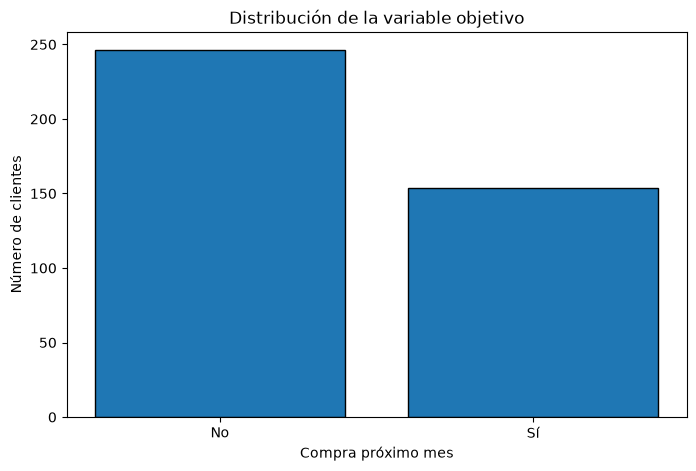

In [36]:
# TODO: gráfico de barras
conteos_target = df["compra_proximo_mes"].value_counts()


plt.figure(figsize=(8, 5))
plt.bar(conteos_target.index, conteos_target.values, edgecolor="black")
plt.xlabel("Compra próximo mes")
plt.ylabel("Número de clientes")
plt.title("Distribución de la variable objetivo")
plt.show()

### Interpretación
¿Las clases aparecen aproximadamente con la misma frecuencia? Justifica con datos.

No, las clases no aparecen con la misma frecuencia. La clase "No" tiene 246 clientes, que es el 61,50% del dataset y la clase "Sí" tiene 154, que es el 38.50% del dataset, por lo que hay una diferencia porcentual de 23 puntos. No es un desequilibrio extremo, pero sí apreciable, y hay que tenerlo en cuenta al entrenar un modelo: uno que respondiera siempre "No" ya acertaría el 61,50 % de las veces sin haber aprendido nada.

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [13]:
# TODO: describe() solo sobre las columnas indicadas

### Interpretación
Escribe una conclusión breve para cada variable:
- **edad:**
- **ingresos_anuales:**
- **gasto_mensual:**
- **num_compras:**
- **devoluciones:**

### Ejercicio 15 - Detectar algo sospechoso
1. ¿Hay algún valor poco razonable?
2. ¿En qué variable?
3. ¿Por qué es sospechoso?
4. ¿Lo eliminarías inmediatamente?
5. ¿Qué comprobarías antes?

**Respuesta:** Escribe aquí.

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

In [14]:
# TODO: histograma de edad

In [15]:
# TODO: histograma de ingresos_anuales

In [16]:
# TODO: histograma de gasto_mensual

In [17]:
# TODO: histograma de num_compras

### Observaciones
- **edad:**
- **ingresos_anuales:**
- **gasto_mensual:**
- **num_compras:**

## Parte 9 - Un mismo dataset, diferentes problemas
### Ejercicio 17 - Problema A
> ¿Realizará el cliente una compra el próximo mes?

Completa y justifica:
- Target:
- ¿Existe \(y\)?:
- Supervisado / no supervisado:
- Clasificación / regresión / clustering:
- Binaria / multiclase:

### Ejercicio 18 - Problema B
Supón una columna `gasto_proximo_mes` con cantidades monetarias.

> ¿Cuánto gastará el cliente el próximo mes?

1. ¿Cuál sería \(y\)?
2. ¿Qué tipo de variable?
3. ¿Supervisado?
4. ¿Clasificación o regresión?
5. ¿Por qué?

**Respuesta:** Escribe aquí.

### Ejercicio 19 - Problema C
> Descubrir grupos de clientes similares sin grupos definidos previamente.

1. ¿Existe etiqueta de grupo?
2. ¿Necesitamos \(y\)?
3. ¿Supervisado o no supervisado?
4. ¿Qué técnica usaríamos?
5. ¿Qué variables podrían describir los grupos?

**Respuesta:** Escribe aquí.

## Parte 10 - Razonamiento
### Ejercicio 20 - ¿Una columna puede cambiar de papel?
¿Por qué una misma variable puede actuar como característica en un problema y como objetivo en otro?

**Respuesta:** Escribe aquí.

### Ejercicio 21 - ¿Qué está mal aquí?
Un compañero hace:

```python
X = df.drop(columns=["compra_proximo_mes"])
y = df["compra_proximo_mes"]
```

y afirma que todas las columnas de `X` ya son características adecuadas.

¿Estás de acuerdo? Identifica al menos dos cuestiones que revisarías.

**Respuesta:** Escribe aquí.

## Parte 11 - Ficha técnica
### Ejercicio 22

```text
FICHA DEL DATASET
=================
Nombre: Clientes e-commerce
Número de muestras:
Número de columnas:
Unidad de observación:
Identificador:
Target:
Tipo de target:
Número de features candidatas:
Features numéricas:
Features categóricas nominales:
Features ordinales:
Datos etiquetados:
Valores ausentes:
Problema principal:
Tipo de aprendizaje:
Tipo de tarea:
```

## Parte 12 - Conclusiones
### Ejercicio 23
Escribe entre **10 y 15 líneas** incluyendo: muestra, dimensiones, columnas vs. features, identificador, tipos de variables, target, \(X\), \(y\), etiquetado, ausentes, distribuciones, posible problema de calidad y tipo de problema de ML.

### Conclusiones
Escribe aquí.

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [18]:
# TODO: ampliación opcional

# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

**Nombre recomendado:** `Practica_04_Apellido_Nombre.ipynb`